In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

# 2023 embedding

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [4]:
df_all = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc.root', "MatchedTree"),\
              'w<1')

In [5]:
print(max(df_all['nefs']))

0.89999920129776


In [6]:
df_allreco = applyCut(df_all, 'pts>15 and bs!=-9 and nefs<0.9')

In [7]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

/tmp/ipykernel_2746788/1944732332.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_allreco['distance1'] = distance1
/tmp/ipykernel_2746788/1944732332.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_allreco['distance2'] = distance2


In [15]:
y1, yerr1 = calc_hist(df_allreco['distance1'], weights=df_allreco['ws'], bins=np.arange(0, 0.055, 0.005), density=True)[:2]
y2, yerr2 = calc_hist(df_allreco['distance2'], weights=df_allreco['ws'], bins=np.arange(0, 0.055, 0.005), density=True)[:2]

In [9]:
plt.rcParams['font.size'] = 15

Text(0.015, 3, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$, $|\\eta|<0.6$\n$p_{\\mathrm{T,jet}}^{\\mathrm{tru}}>5$ GeV$/c$, $p_{\\mathrm{T,jet}}^{\\mathrm{det}}>15$ GeV$/c$')

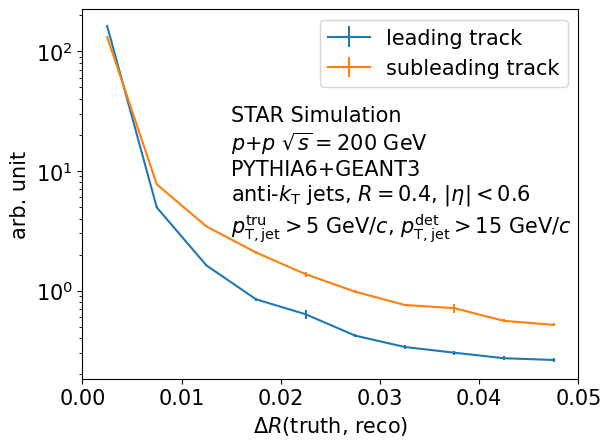

In [16]:
plt.errorbar(np.arange(0.0025, 0.04975, 0.005), y1, xerr=0., yerr=yerr1, label='leading track')
plt.errorbar(np.arange(0.0025, 0.04975, 0.005), y2, xerr=0., yerr=yerr2, label='subleading track')
plt.xticks(np.arange(0, 0.06, 0.01))
plt.xlabel('$\Delta R$(truth, reco)')
plt.yscale('log')
plt.ylabel('arb. unit')
plt.legend()
plt.text(0.015, 3, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$\n$p_{\mathrm{T,jet}}^{\mathrm{tru}}>5$ GeV$/c$, $p_{\mathrm{T,jet}}^{\mathrm{det}}>15$ GeV$/c$', fontsize=15)

In [11]:
sum(y1[0:4])/sum(y1)*sum(y2[0:4])/sum(y2)

0.9546422011282462

In [17]:
df_allreco = applyCut(df_allreco, 'pts>20')

In [18]:
y1, yerr1 = calc_hist(df_allreco['distance1'], weights=df_allreco['ws'], bins=np.arange(0, 0.055, 0.005), density=True)[:2]
y2, yerr2 = calc_hist(df_allreco['distance2'], weights=df_allreco['ws'], bins=np.arange(0, 0.055, 0.005), density=True)[:2]

Text(0.015, 3, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$, $|\\eta|<0.6$\n$p_{\\mathrm{T,jet}}^{\\mathrm{tru}}>5$ GeV$/c$, $p_{\\mathrm{T,jet}}^{\\mathrm{det}}>20$ GeV$/c$')

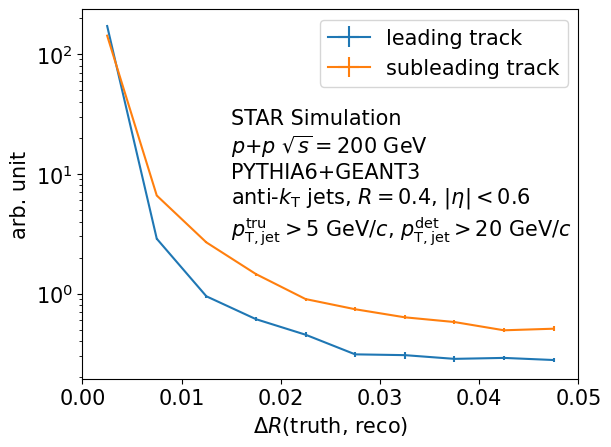

In [19]:
plt.errorbar(np.arange(0.0025, 0.04975, 0.005), y1, xerr=0., yerr=yerr1, label='leading track')
plt.errorbar(np.arange(0.0025, 0.04975, 0.005), y2, xerr=0., yerr=yerr2, label='subleading track')
plt.xticks(np.arange(0, 0.06, 0.01))
plt.xlabel('$\Delta R$(truth, reco)')
plt.yscale('log')
plt.ylabel('arb. unit')
plt.legend()
plt.text(0.015, 3, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$\n$p_{\mathrm{T,jet}}^{\mathrm{tru}}>5$ GeV$/c$, $p_{\mathrm{T,jet}}^{\mathrm{det}}>20$ GeV$/c$', fontsize=15)

# 2015 embedding

In [3]:
observables1 = ['pt','b','w','reject','pt1','pt2','y1','y2','phi1','phi2','evid','nef']
observabless1 = ['pts','bs','ws','rejects','pt1s','pt2s','y1s','y2s','phi1s','phi2s','evids','nefs']

In [4]:
df_all = applyCut(getData(observables1+observabless1, '/gpfs/gibbs/project/havener/ys668/other_output/rc/all0615_final.root', "MatchedTree"),\
              'reject<=0 and rejects<=0')

In [5]:
df_allreco = applyCut(df_all, 'pts>15 and bs!=-9 and nefs<0.9')

In [6]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

/tmp/ipykernel_457516/1944732332.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_allreco['distance1'] = distance1
/tmp/ipykernel_457516/1944732332.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_allreco['distance2'] = distance2


In [7]:
plt.rcParams.update({'font.size': 15})

In [8]:
y1, yerr1 = calc_hist(df_allreco['distance1'], weights=df_allreco['ws'], bins=np.arange(0, 0.055, 0.005), density=True)[:2]
y2, yerr2 = calc_hist(df_allreco['distance2'], weights=df_allreco['ws'], bins=np.arange(0, 0.055, 0.005), density=True)[:2]

Text(0.015, 3, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$, $|\\eta|<0.6$\n$p_{\\mathrm{T,jet}}^{\\mathrm{tru}}>5$ GeV$/c$, $p_{\\mathrm{T,jet}}^{\\mathrm{det}}>15$ GeV$/c$')

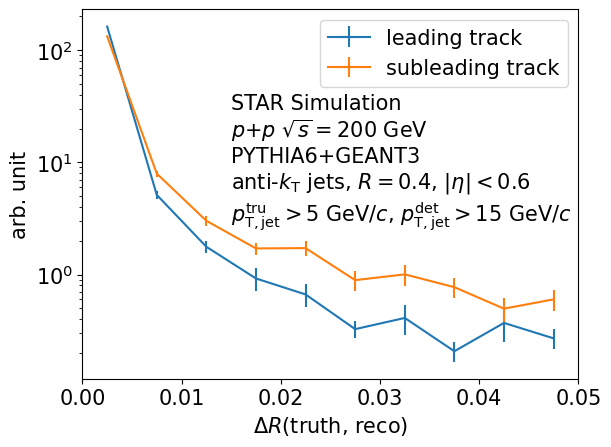

In [9]:
plt.errorbar(np.arange(0.0025, 0.04975, 0.005), y1, xerr=0., yerr=yerr1, label='leading track')
plt.errorbar(np.arange(0.0025, 0.04975, 0.005), y2, xerr=0., yerr=yerr2, label='subleading track')
plt.xticks(np.arange(0, 0.06, 0.01))
plt.xlabel('$\Delta R$(truth, reco)')
plt.yscale('log')
plt.ylabel('arb. unit')
plt.legend()
plt.text(0.015, 3, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$\n$p_{\mathrm{T,jet}}^{\mathrm{tru}}>5$ GeV$/c$, $p_{\mathrm{T,jet}}^{\mathrm{det}}>15$ GeV$/c$', fontsize=15)

In [26]:
sum(y1[0:4])/sum(y1)*sum(y2[0:4])/sum(y2)

0.9510955630466237

In [27]:
y1, yerr1 = calc_hist(df_allreco['distance1'], weights=df_allreco['ws'], bins=np.arange(0, 0.205, 0.005), density=True)[:2]
y2, yerr2 = calc_hist(df_allreco['distance2'], weights=df_allreco['ws'], bins=np.arange(0, 0.205, 0.005), density=True)[:2]

Text(0.015, 5, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$, $|\\eta|<0.6$')

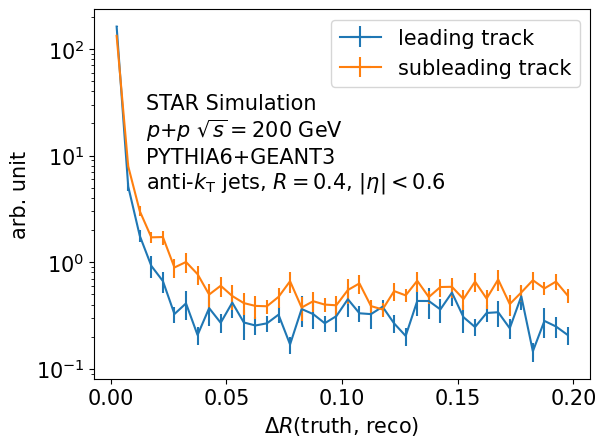

In [28]:
plt.errorbar(np.arange(0.0025, 0.2025, 0.005), y1, xerr=0., yerr=yerr1, label='leading track')
plt.errorbar(np.arange(0.0025, 0.2025, 0.005), y2, xerr=0., yerr=yerr2, label='subleading track')
plt.xlabel('$\Delta R$(truth, reco)')
plt.yscale('log')
plt.ylabel('arb. unit')
plt.legend()
plt.text(0.015, 5, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=15)

In [29]:
sum(y1[0:4])/sum(y1)*sum(y2[0:4])/sum(y2)

0.8188415073286575

In [30]:
y1, yerr1 = calc_hist(df_allreco[df_allreco.distance1<0.02]['pt1s'], weights=df_allreco[df_allreco.distance1<0.02]['ws'], bins=np.arange(0, 21), density=True)[:2]
y2, yerr2 = calc_hist(df_allreco[df_allreco.distance2<0.02]['pt2s'], weights=df_allreco[df_allreco.distance2<0.02]['ws'], bins=np.arange(0, 21), density=True)[:2]

Text(0.5, 1.0, '$\\Delta R$(truth, reco) < 0.02')

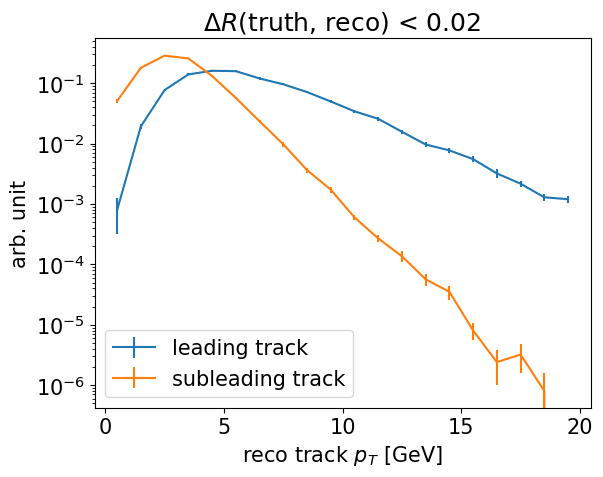

In [31]:
plt.errorbar(np.arange(0.5,20.5), y1, xerr=0., yerr=yerr1, label='leading track')
plt.errorbar(np.arange(0.5,20.5), y2, xerr=0., yerr=yerr2, label='subleading track')
plt.xlabel('reco track $p_T$ [GeV]')
plt.yscale('log')
plt.ylabel('arb. unit')
plt.legend()
plt.title('$\Delta R$(truth, reco) < 0.02')
#plt.text(0.015, 3, '$p_{\mathrm{T,jet}}^{\mathrm{tru}}>5$ GeV$/c$, $p_{\mathrm{T,jet}}^{\mathrm{det}}>20$ GeV$/c$', fontsize=15)

In [32]:
print(np.average(df_allreco[df_allreco.distance1<0.02]['pt1s'], weights=df_allreco[df_allreco.distance1<0.02]['ws']))
print(np.average(df_allreco[df_allreco.distance2<0.02]['pt2s'], weights=df_allreco[df_allreco.distance2<0.02]['ws']))

6.248791654567565
3.0888039551002007


In [33]:
y1, yerr1 = calc_hist(df_allreco[df_allreco.distance1>0.02]['pt1s'], weights=df_allreco[df_allreco.distance1>0.02]['ws'], bins=np.arange(0, 21), density=True)[:2]
y2, yerr2 = calc_hist(df_allreco[df_allreco.distance2>0.02]['pt2s'], weights=df_allreco[df_allreco.distance2>0.02]['ws'], bins=np.arange(0, 21), density=True)[:2]

Text(0.5, 1.0, '$\\Delta R$(truth, reco) > 0.02')

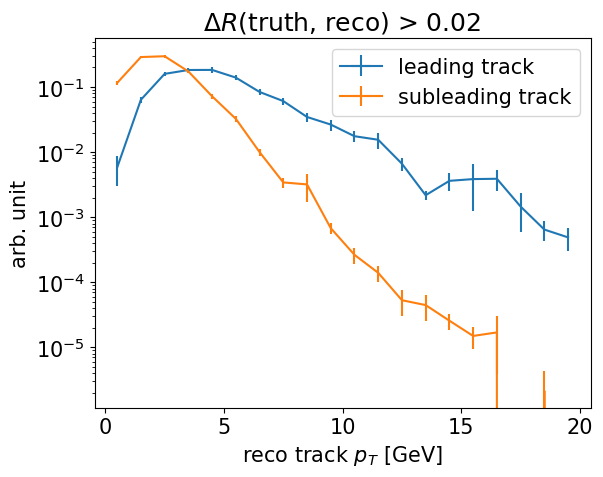

In [34]:
plt.errorbar(np.arange(0.5,20.5), y1, xerr=0., yerr=yerr1, label='leading track')
plt.errorbar(np.arange(0.5,20.5), y2, xerr=0., yerr=yerr2, label='subleading track')
plt.xlabel('reco track $p_T$ [GeV]')
plt.yscale('log')
plt.ylabel('arb. unit')
plt.legend()
plt.title('$\Delta R$(truth, reco) > 0.02')
#plt.text(0.015, 3, '$p_{\mathrm{T,jet}}^{\mathrm{tru}}>5$ GeV$/c$, $p_{\mathrm{T,jet}}^{\mathrm{det}}>20$ GeV$/c$', fontsize=15)

In [35]:
print(np.average(df_allreco[df_allreco.distance1>0.02]['pt1s'], weights=df_allreco[df_allreco.distance1>0.02]['ws']))
print(np.average(df_allreco[df_allreco.distance2>0.02]['pt2s'], weights=df_allreco[df_allreco.distance2>0.02]['ws']))

5.026981683515224
2.483048857688216


In [10]:
df_allreco = applyCut(df_allreco, 'pts>20')

In [11]:
y1, yerr1 = calc_hist(df_allreco['distance1'], weights=df_allreco['ws'], bins=np.arange(0, 0.055, 0.005), density=True)[:2]
y2, yerr2 = calc_hist(df_allreco['distance2'], weights=df_allreco['ws'], bins=np.arange(0, 0.055, 0.005), density=True)[:2]

Text(0.015, 3, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$, $|\\eta|<0.6$\n$p_{\\mathrm{T,jet}}^{\\mathrm{tru}}>5$ GeV$/c$, $p_{\\mathrm{T,jet}}^{\\mathrm{det}}>20$ GeV$/c$')

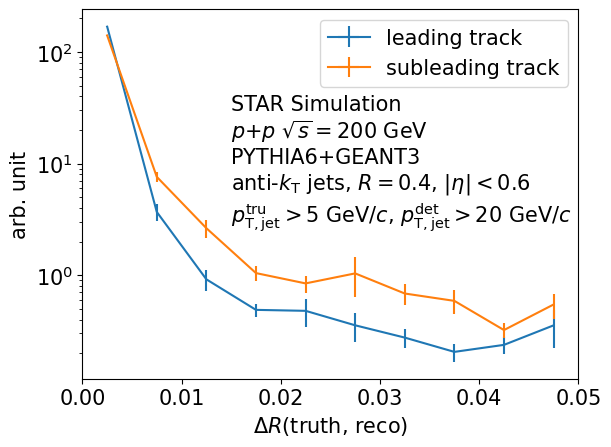

In [12]:
plt.errorbar(np.arange(0.0025, 0.04975, 0.005), y1, xerr=0., yerr=yerr1, label='leading track')
plt.errorbar(np.arange(0.0025, 0.04975, 0.005), y2, xerr=0., yerr=yerr2, label='subleading track')
plt.xticks(np.arange(0, 0.06, 0.01))
plt.xlabel('$\Delta R$(truth, reco)')
plt.yscale('log')
plt.ylabel('arb. unit')
plt.legend()
plt.text(0.015, 3, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$\n$p_{\mathrm{T,jet}}^{\mathrm{tru}}>5$ GeV$/c$, $p_{\mathrm{T,jet}}^{\mathrm{det}}>20$ GeV$/c$', fontsize=15)

In [12]:
y1, yerr1 = calc_hist(df_allreco[df_allreco.distance1<0.02]['pt1s'], weights=df_allreco[df_allreco.distance1<0.02]['ws'], bins=np.arange(0, 21), density=True)[:2]
y2, yerr2 = calc_hist(df_allreco[df_allreco.distance2<0.02]['pt2s'], weights=df_allreco[df_allreco.distance2<0.02]['ws'], bins=np.arange(0, 21), density=True)[:2]

Text(0.5, 1.0, '$\\Delta R$(truth, reco) < 0.02')

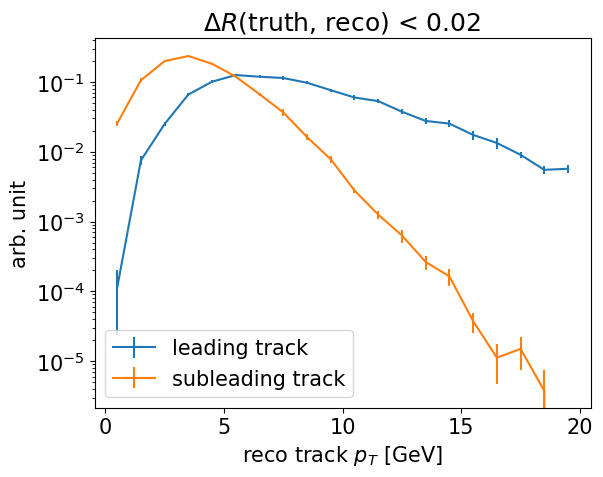

In [14]:
plt.errorbar(np.arange(0.5,20.5), y1, xerr=0., yerr=yerr1, label='leading track')
plt.errorbar(np.arange(0.5,20.5), y2, xerr=0., yerr=yerr2, label='subleading track')
plt.xlabel('reco track $p_T$ [GeV]')
plt.yscale('log')
plt.ylabel('arb. unit')
plt.legend()
plt.title('$\Delta R$(truth, reco) < 0.02')
#plt.text(0.015, 3, '$p_{\mathrm{T,jet}}^{\mathrm{tru}}>5$ GeV$/c$, $p_{\mathrm{T,jet}}^{\mathrm{det}}>20$ GeV$/c$', fontsize=15)

In [17]:
print(np.average(df_allreco[df_allreco.distance1<0.02]['pt1s'], weights=df_allreco[df_allreco.distance1<0.02]['ws']))
print(np.average(df_allreco[df_allreco.distance2<0.02]['pt2s'], weights=df_allreco[df_allreco.distance2<0.02]['ws']))

8.249735097087337
3.9557246265384958


In [18]:
y1, yerr1 = calc_hist(df_allreco[df_allreco.distance1>0.02]['pt1s'], weights=df_allreco[df_allreco.distance1>0.02]['ws'], bins=np.arange(0, 21), density=True)[:2]
y2, yerr2 = calc_hist(df_allreco[df_allreco.distance2>0.02]['pt2s'], weights=df_allreco[df_allreco.distance2>0.02]['ws'], bins=np.arange(0, 21), density=True)[:2]

Text(0.5, 1.0, '$\\Delta R$(truth, reco) > 0.02')

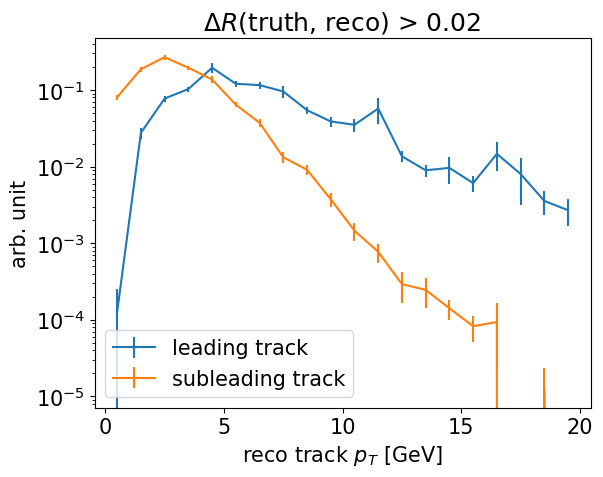

In [19]:
plt.errorbar(np.arange(0.5,20.5), y1, xerr=0., yerr=yerr1, label='leading track')
plt.errorbar(np.arange(0.5,20.5), y2, xerr=0., yerr=yerr2, label='subleading track')
plt.xlabel('reco track $p_T$ [GeV]')
plt.yscale('log')
plt.ylabel('arb. unit')
plt.legend()
plt.title('$\Delta R$(truth, reco) > 0.02')
#plt.text(0.015, 3, '$p_{\mathrm{T,jet}}^{\mathrm{tru}}>5$ GeV$/c$, $p_{\mathrm{T,jet}}^{\mathrm{det}}>20$ GeV$/c$', fontsize=15)

In [20]:
print(np.average(df_allreco[df_allreco.distance1>0.02]['pt1s'], weights=df_allreco[df_allreco.distance1>0.02]['ws']))
print(np.average(df_allreco[df_allreco.distance2>0.02]['pt2s'], weights=df_allreco[df_allreco.distance2>0.02]['ws']))

6.751349746265247
3.1486475120207063


In [15]:
y1, yerr1 = calc_hist(df_allreco['distance1'], weights=df_allreco['ws'], bins=np.arange(0, 0.205, 0.005), density=True)[:2]
y2, yerr2 = calc_hist(df_allreco['distance2'], weights=df_allreco['ws'], bins=np.arange(0, 0.205, 0.005), density=True)[:2]

Text(0.015, 5, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$, $|\\eta|<0.6$')

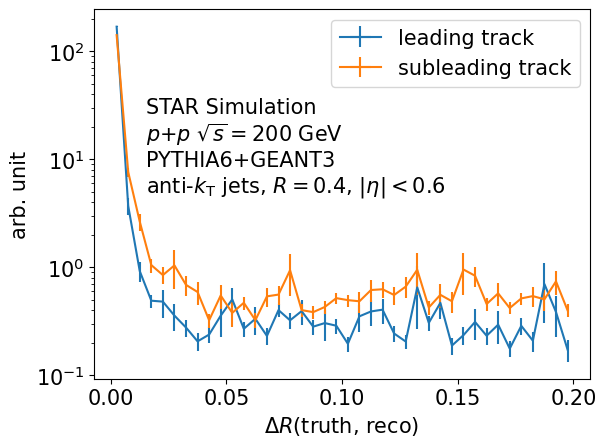

In [16]:
plt.errorbar(np.arange(0.0025, 0.2025, 0.005), y1, xerr=0., yerr=yerr1, label='leading track')
plt.errorbar(np.arange(0.0025, 0.2025, 0.005), y2, xerr=0., yerr=yerr2, label='subleading track')
plt.xlabel('$\Delta R$(truth, reco)')
plt.yscale('log')
plt.ylabel('arb. unit')
plt.legend()
plt.text(0.015, 5, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=15)

In [17]:
sum(y1[0:4])/sum(y1)

0.9373649692397875

In [18]:
sum(y2[0:4])/sum(y2)

0.8802489934739044

In [27]:
y1, yerr1 = calc_hist(df_allreco[df_allreco.pt1s>5]['distance1'], weights=df_allreco[df_allreco.pt1s>5]['ws'], bins=np.arange(0, 0.205, 0.005), density=True)[:2]
y2, yerr2 = calc_hist(df_allreco[df_allreco.pt2s>5]['distance2'], weights=df_allreco[df_allreco.pt2s>5]['ws'], bins=np.arange(0, 0.205, 0.005), density=True)[:2]

Text(0.015, 5, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$, $|\\eta|<0.6$')

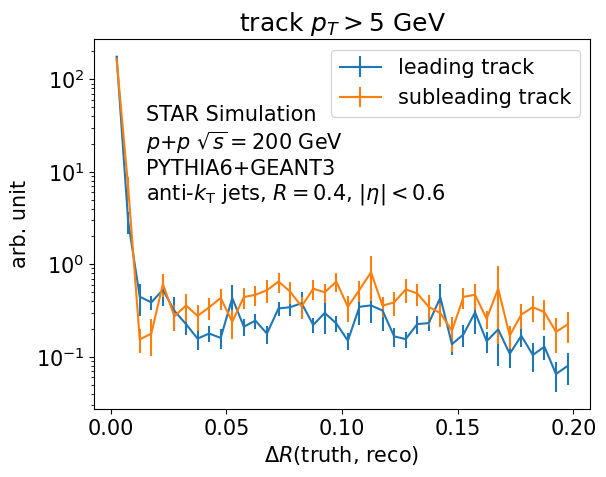

In [28]:
plt.errorbar(np.arange(0.0025, 0.2025, 0.005), y1, xerr=0., yerr=yerr1, label='leading track')
plt.errorbar(np.arange(0.0025, 0.2025, 0.005), y2, xerr=0., yerr=yerr2, label='subleading track')
plt.xlabel('$\Delta R$(truth, reco)')
plt.yscale('log')
plt.ylabel('arb. unit')
plt.legend()
plt.title('track $p_T>5$ GeV')
plt.text(0.015, 5, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=15)

In [29]:
sum(y1[0:4])/sum(y1)

0.9551765074140801

In [30]:
sum(y2[0:4])/sum(y2)

0.9212669569716555